In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import glob
import os
import re


In [4]:
df = pd.read_csv("Processed_Flipdata - Processed_Flipdata.csv")
df.head()

,Unnamed: 0,Model,Colour,Memory,RAM,Battery_,Rear Camera,Front Camera,AI Lens,Mobile Height,Processor_,Prize
0,0,Infinix SMART 7,Night Black,64,4,6000,13MP,5MP,1,16.76,Unisoc Spreadtrum SC9863A1,"7,299"
1,1,Infinix SMART 7,Azure Blue,64,4,6000,13MP,5MP,1,16.76,Unisoc Spreadtrum SC9863A1,"7,299"
2,2,MOTOROLA G32,Mineral Gray,128,8,5000,50MP,16MP,0,16.64,Qualcomm Snapdragon 680,"11,999"
3,3,POCO C50,Royal Blue,32,2,5000,8MP,5MP,0,16.56,Mediatek Helio A22,"5,649"
4,4,Infinix HOT 30i,Marigold,128,8,5000,50MP,5MP,1,16.76,G37,"8,999"


In [5]:
print(df.head())

   Unnamed: 0            Model        Colour  Memory  RAM  Battery_  \
0           0  Infinix SMART 7   Night Black      64    4      6000   
1           1  Infinix SMART 7    Azure Blue      64    4      6000   
2           2     MOTOROLA G32  Mineral Gray     128    8      5000   
3           3         POCO C50    Royal Blue      32    2      5000   
4           4  Infinix HOT 30i      Marigold     128    8      5000   

  Rear Camera Front Camera  AI Lens  Mobile Height  \
0        13MP          5MP        1          16.76   
1        13MP          5MP        1          16.76   
2        50MP         16MP        0          16.64   
3         8MP          5MP        0          16.56   
4        50MP          5MP        1          16.76   

                   Processor_   Prize  
0  Unisoc Spreadtrum SC9863A1   7,299  
1  Unisoc Spreadtrum SC9863A1   7,299  
2     Qualcomm Snapdragon 680  11,999  
3          Mediatek Helio A22   5,649  
4                         G37   8,999  


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541 entries, 0 to 540
Data columns (total 12 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Unnamed: 0     541 non-null    int64  
 1   Model          541 non-null    object 
 2   Colour         541 non-null    object 
 3   Memory         541 non-null    int64  
 4   RAM            541 non-null    int64  
 5   Battery_       541 non-null    int64  
 6   Rear Camera    541 non-null    object 
 7   Front Camera   541 non-null    object 
 8   AI Lens        541 non-null    int64  
 9   Mobile Height  541 non-null    float64
 10  Processor_     541 non-null    object 
 11  Prize          541 non-null    object 
dtypes: float64(1), int64(5), object(6)
memory usage: 50.8+ KB


In [7]:
# Dataset shape
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("\nData Types:\n", df.dtypes)
print("\nMissing Values:\n", df.isnull().sum())
print("\nColumns:\n", df.columns.tolist())

Rows: 541
Columns: 12

Data Types:
 Unnamed: 0         int64
Model             object
Colour            object
Memory             int64
RAM                int64
Battery_           int64
Rear Camera       object
Front Camera      object
AI Lens            int64
Mobile Height    float64
Processor_        object
Prize             object
dtype: object

Missing Values:
 Unnamed: 0       0
Model            0
Colour           0
Memory           0
RAM              0
Battery_         0
Rear Camera      0
Front Camera     0
AI Lens          0
Mobile Height    0
Processor_       0
Prize            0
dtype: int64

Columns:
 ['Unnamed: 0', 'Model', 'Colour', 'Memory', 'RAM', 'Battery_', 'Rear Camera', 'Front Camera', 'AI Lens', 'Mobile Height', 'Processor_', 'Prize']


In [8]:
# Check Duplicate
print("\n--- Duplicate Check---")
print(f"Total duplicates: {df.duplicated().sum()}")
print(f"Duplicate %: {df.duplicated().sum()/len(df) * 100:.2f}%")
print(df.duplicated().sum())


--- Duplicate Check---
Total duplicates: 0
Duplicate %: 0.00%
0


In [9]:
# Remobve duplicates if any
df_before = df.shape[0]
df = df.drop_duplicates()
print(f"After removing duplicates: {df.shape[0]} rows "
    f"(Removed {df_before - df.shape[0]})")

After removing duplicates: 541 rows (Removed 0)


In [10]:
df.duplicated()

0      False
1      False
2      False
3      False
4      False
       ...  
536    False
537    False
538    False
539    False
540    False
Length: 541, dtype: bool

In [11]:
df['Model'].duplicated().sum()

np.int64(354)

In [12]:
df.describe()

,Unnamed: 0,Memory,RAM,Battery_,AI Lens,Mobile Height
count,541.000000,541.000000,541.000000,541.000000,541.000000,541.000000
mean,289.711645,110.550832,5.397412,4871.587800,0.062847,16.431201
std,182.359185,60.600694,1.984923,780.148862,0.242911,2.523553
min,0.000000,16.000000,2.000000,800.000000,0.000000,4.500000
25%,135.000000,64.000000,4.000000,5000.000000,0.000000,16.510000
50%,273.000000,128.000000,6.000000,5000.000000,0.000000,16.710000
75%,434.000000,128.000000,8.000000,5000.000000,0.000000,16.940000
max,642.000000,256.000000,8.000000,7000.000000,1.000000,41.940000


In [13]:
# Summary statistics for categorical (text) columns
print(df.describe(include=['object', 'string']))

           Model  Colour Rear Camera Front Camera               Processor_  \
count        541     541         541          541                      541   
unique       187     275          14           13                      123   
top     vivo Y16  Yellow        50MP         16MP  Qualcomm Snapdragon 680   
freq           9      12         260          164                       33   

         Prize  
count      541  
unique     158  
top     15,999  
freq        23  


In [14]:
print(df.describe(include='all'))

        Unnamed: 0     Model  Colour      Memory         RAM     Battery_  \
count   541.000000       541     541  541.000000  541.000000   541.000000   
unique         NaN       187     275         NaN         NaN          NaN   
top            NaN  vivo Y16  Yellow         NaN         NaN          NaN   
freq           NaN         9      12         NaN         NaN          NaN   
mean    289.711645       NaN     NaN  110.550832    5.397412  4871.587800   
std     182.359185       NaN     NaN   60.600694    1.984923   780.148862   
min       0.000000       NaN     NaN   16.000000    2.000000   800.000000   
25%     135.000000       NaN     NaN   64.000000    4.000000  5000.000000   
50%     273.000000       NaN     NaN  128.000000    6.000000  5000.000000   
75%     434.000000       NaN     NaN  128.000000    8.000000  5000.000000   
max     642.000000       NaN     NaN  256.000000    8.000000  7000.000000   

       Rear Camera Front Camera     AI Lens  Mobile Height  \
count        

In [15]:
# Fetching the unique values

print("\n--- First 9 rows ---")
print(df.head())


--- First 9 rows ---
   Unnamed: 0            Model        Colour  Memory  RAM  Battery_  \
0           0  Infinix SMART 7   Night Black      64    4      6000   
1           1  Infinix SMART 7    Azure Blue      64    4      6000   
2           2     MOTOROLA G32  Mineral Gray     128    8      5000   
3           3         POCO C50    Royal Blue      32    2      5000   
4           4  Infinix HOT 30i      Marigold     128    8      5000   

  Rear Camera Front Camera  AI Lens  Mobile Height  \
0        13MP          5MP        1          16.76   
1        13MP          5MP        1          16.76   
2        50MP         16MP        0          16.64   
3         8MP          5MP        0          16.56   
4        50MP          5MP        1          16.76   

                   Processor_   Prize  
0  Unisoc Spreadtrum SC9863A1   7,299  
1  Unisoc Spreadtrum SC9863A1   7,299  
2     Qualcomm Snapdragon 680  11,999  
3          Mediatek Helio A22   5,649  
4                         

In [16]:
print("\n--- Last 7 rows ---")
print(df.tail())


--- Last 7 rows ---
     Unnamed: 0                  Model          Colour  Memory  RAM  Battery_  \
536         637  SAMSUNG Galaxy S23 5G           Cream     256    8      3900   
537         638               LAVA Z21            Cyan      32    2      3100   
538         639         Tecno Spark 8T  Turquoise Cyan      64    4      5000   
539         641  SAMSUNG Galaxy A54 5G    Awesome Lime     128    8      5000   
540         642               OPPO A77        Sky Blue     128    4      5000   

    Rear Camera Front Camera  AI Lens  Mobile Height  \
536        50MP         12MP        0          15.49   
537         5MP          2MP        0          12.70   
538        50MP          8MP        0          16.76   
539        50MP         32MP        0          16.26   
540        50MP          8MP        0          16.66   

                      Processor_   Prize  
536  Qualcomm Snapdragon 8 Gen 2  79,999  
537                    Octa Core   5,998  
538           MediaTek Hel

In [17]:
print("\n--- Random 6 rows ---")
print(df.sample(6))


--- Random 6 rows ---
     Unnamed: 0              Model         Colour  Memory  RAM  Battery_  \
432         479           vivo Y16  Stellar Black     128    4      5000   
156         156         micromax 3   Nebula Green     256    4      1020   
22           22        vivo T2x 5G  Glimmer Black     128    8      5000   
479         553           POCO C31     Royal Blue      64    4      5000   
488         568       REDMI Note 9    Scarlet Red     128    6      5020   
389         414  realme 10 Pro+ 5G    Nebula Blue     128    6      5000   

    Rear Camera Front Camera  AI Lens  Mobile Height  \
432        13MP          5MP        0          16.54   
156         2MP          0MP        0           6.10   
22         50MP          8MP        0          16.71   
479        13MP          5MP        0          16.59   
488        48MP         13MP        0          16.59   
389       108MP         16MP        0          17.02   

                     Processor_   Prize  
432      

In [18]:
print(df[df['Model'] == 'Prize'].head(3))

Empty DataFrame
Columns: [Unnamed: 0, Model, Colour, Memory, RAM, Battery_, Rear Camera, Front Camera, AI Lens, Mobile Height, Processor_, Prize]
Index: []


In [19]:
# Remove currency symbols/commas and convert to numbers
df['Prize'] = df['Prize'].astype(str).str.replace(r'[^\d.]', '', regex=True)
df['Prize'] = pd.to_numeric(df['Prize'])

print(df[df['Prize'] > 1000].head(3))

   Unnamed: 0            Model        Colour  Memory  RAM  Battery_  \
0           0  Infinix SMART 7   Night Black      64    4      6000   
1           1  Infinix SMART 7    Azure Blue      64    4      6000   
2           2     MOTOROLA G32  Mineral Gray     128    8      5000   

  Rear Camera Front Camera  AI Lens  Mobile Height  \
0        13MP          5MP        1          16.76   
1        13MP          5MP        1          16.76   
2        50MP         16MP        0          16.64   

                   Processor_  Prize  
0  Unisoc Spreadtrum SC9863A1   7299  
1  Unisoc Spreadtrum SC9863A1   7299  
2     Qualcomm Snapdragon 680  11999  


In [20]:
# Info & Missing Values
print("\n--- Info ---")
print(df.info())


--- Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541 entries, 0 to 540
Data columns (total 12 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Unnamed: 0     541 non-null    int64  
 1   Model          541 non-null    object 
 2   Colour         541 non-null    object 
 3   Memory         541 non-null    int64  
 4   RAM            541 non-null    int64  
 5   Battery_       541 non-null    int64  
 6   Rear Camera    541 non-null    object 
 7   Front Camera   541 non-null    object 
 8   AI Lens        541 non-null    int64  
 9   Mobile Height  541 non-null    float64
 10  Processor_     541 non-null    object 
 11  Prize          541 non-null    int64  
dtypes: float64(1), int64(6), object(5)
memory usage: 50.8+ KB
None


In [21]:
print("\n--- Missing Values ---")
print(df.isnull().sum())


--- Missing Values ---
Unnamed: 0       0
Model            0
Colour           0
Memory           0
RAM              0
Battery_         0
Rear Camera      0
Front Camera     0
AI Lens          0
Mobile Height    0
Processor_       0
Prize            0
dtype: int64


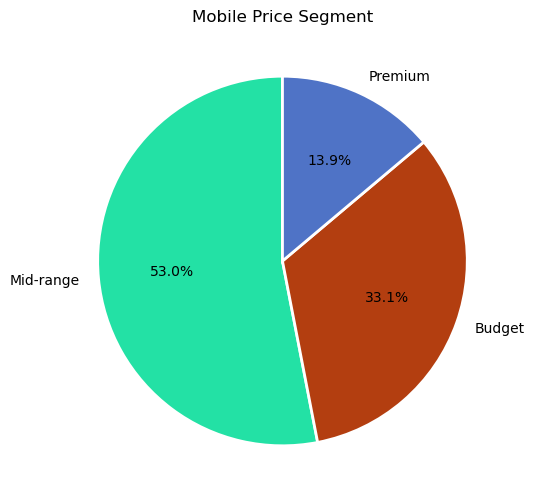

price_segment
Mid-range    287
Budget       179
Premium       75
Name: count, dtype: int64


In [22]:
#Price Segment
df['price_segment'] = pd.cut(
    df['Prize'],
    bins=[0, 10000, 25000, np.inf],
    labels=['Budget', 'Mid-range', 'Premium'],
    include_lowest=True
)
price_counts = df['price_segment'].value_counts()

plt.figure(figsize=(6,6))
plt.pie(price_counts.values, 
        labels=price_counts.index, 
        autopct='%1.1f%%',
        colors=["#23e1a5", "#b33e10", "#4f73c6"],
        startangle=90, 
        wedgeprops={'edgecolor':'white', 'linewidth':2})
plt.title('Mobile Price Segment')
plt.show()

print(price_counts)

In [23]:
# FEATURE EXTRACTION

from sklearn.feature_selection import SelectKBest, f_regression

X = df.drop('Prize', axis=1)
y = df['Prize']

# Correlation Analysis
corr = df.corr(numeric_only=True)['Prize'].sort_values(ascending=False)
print(corr)

Prize            1.000000
Memory           0.566660
RAM              0.532024
Unnamed: 0       0.333940
Mobile Height    0.176009
Battery_        -0.034297
AI Lens         -0.153691
Name: Prize, dtype: float64


In [24]:
# SelectKBest
from sklearn.feature_selection import SelectKBest, f_regression

X = X.select_dtypes(include=['number'])  # remove text columns
y = y.fillna(y.median())

print("X shape for SelectKBest:", X.shape)
print(X.columns.tolist())

selector = SelectKBest(score_func=f_regression, k=5)
selector.fit(X, y)
scores = pd.DataFrame({'Feature': X.columns, 'Score': selector.scores_}).sort_values('Score', ascending=False)
print(scores)

X shape for SelectKBest: (541, 6)
['Unnamed: 0', 'Memory', 'RAM', 'Battery_', 'AI Lens', 'Mobile Height']
         Feature       Score
1         Memory  254.935168
2            RAM  212.795810
0     Unnamed: 0   67.651293
5  Mobile Height   17.231581
4        AI Lens   13.039714
3       Battery_    0.634769


C:\Users\Hp\AppData\Local\Temp\ipykernel_12276\2002602439.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Score', y='Feature', data=scores.head(5), palette='viridis')


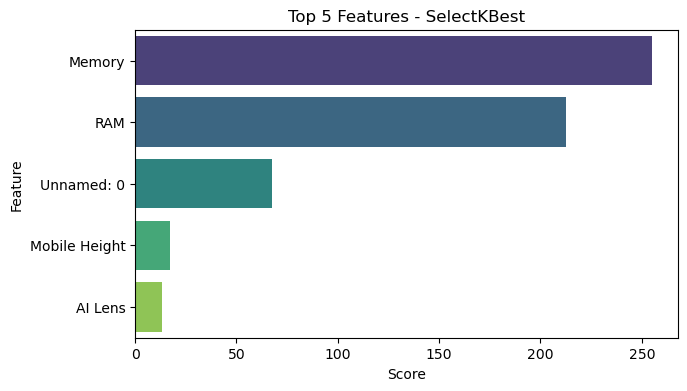

In [25]:
# Plot for report
import seaborn as sns
plt.figure(figsize=(7,4))
sns.barplot(x='Score', y='Feature', data=scores.head(5), palette='viridis')
plt.title('Top 5 Features - SelectKBest')
plt.show()

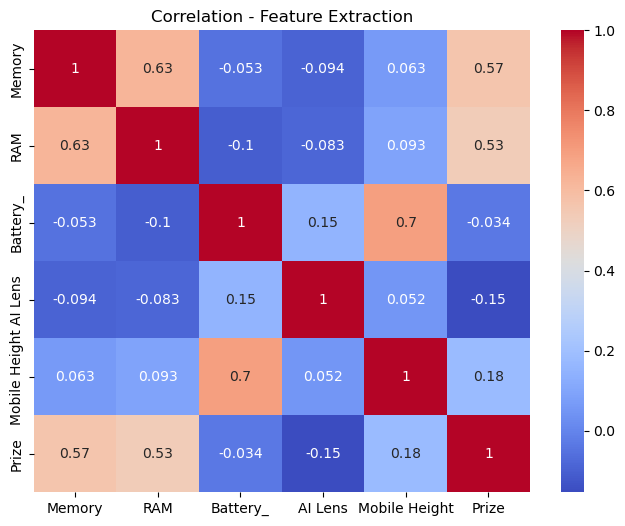

In [26]:
#Visualization - Heatmap

df_clean = df.drop(columns=['Unnamed: 0', 'Model', 'Colour'], errors='ignore')

plt.figure(figsize=(8,6))
sns.heatmap(df_clean.corr(numeric_only=True), annot=True, cmap='coolwarm')
plt.title('Correlation - Feature Extraction')
plt.show()

In [27]:
# MODEL BUILDING

# 1. FUNCTION TO EXTRACT NUMBERS ONLY
def extract_number(val):
    if pd.isna(val):
        return None
    # Find first number in string like '13MP' -> 13, 'Unisoc...' -> None
    match = re.search(r'(\d+\.?\d*)', str(val))
    if match:
        return float(match.group(1))
    return None

# 2. CLEAN ALL COLUMNS
for col in df.columns:
    if col != 'Prize':
        # Try to extract number, if column is object type
        if df[col].dtype == 'object':
            df[col] = df[col].apply(extract_number)

# Prize clean
df['Prize'] = df['Prize'].apply(extract_number)

print(df.head())

# 3. DO NUMERIC ONLY + FILLNA - This will NOT error
X = df.drop('Prize', axis=1)
X = X.select_dtypes(include=['number'])
X = X.fillna(X.median())  # safe now

y = df['Prize']
y = y.fillna(y.median())

print(f"Cleaned X shape: {X.shape}, columns: {list(X.columns)}")

# 4. SPLIT
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 5. TRAIN
models = {
    'Linear Regression': LinearRegression(),
    'Decision Tree': DecisionTreeRegressor(random_state=42),
    'Random Forest': RandomForestRegressor(n_estimators=100, random_state=42),
    'Gradient Boosting': GradientBoostingRegressor(random_state=42)
}

for name, model in models.items():
    model.fit(X_train, y_train)
    print(f"{name} - Done")

print("All models built successfully - No Error!")

   Unnamed: 0  Model  Colour  Memory  RAM  Battery_  Rear Camera  \
0           0    7.0     NaN      64    4      6000         13.0   
1           1    7.0     NaN      64    4      6000         13.0   
2           2   32.0     NaN     128    8      5000         50.0   
3           3   50.0     NaN      32    2      5000          8.0   
4           4   30.0     NaN     128    8      5000         50.0   

   Front Camera  AI Lens  Mobile Height  Processor_    Prize price_segment  
0           5.0        1          16.76      9863.0   7299.0        Budget  
1           5.0        1          16.76      9863.0   7299.0        Budget  
2          16.0        0          16.64       680.0  11999.0     Mid-range  
3           5.0        0          16.56        22.0   5649.0        Budget  
4           5.0        1          16.76        37.0   8999.0        Budget  
Cleaned X shape: (541, 11), columns: ['Unnamed: 0', 'Model', 'Colour', 'Memory', 'RAM', 'Battery_', 'Rear Camera', 'Front Camera'

In [28]:
X = df.drop('Prize', axis=1)
X = X.select_dtypes(include=['number'])
X = X.fillna(X.median())  # safe now

y = df['Prize']
y = y.fillna(y.median())

print(f"Cleaned X shape: {X.shape}, columns: {list(X.columns)}")

Cleaned X shape: (541, 11), columns: ['Unnamed: 0', 'Model', 'Colour', 'Memory', 'RAM', 'Battery_', 'Rear Camera', 'Front Camera', 'AI Lens', 'Mobile Height', 'Processor_']


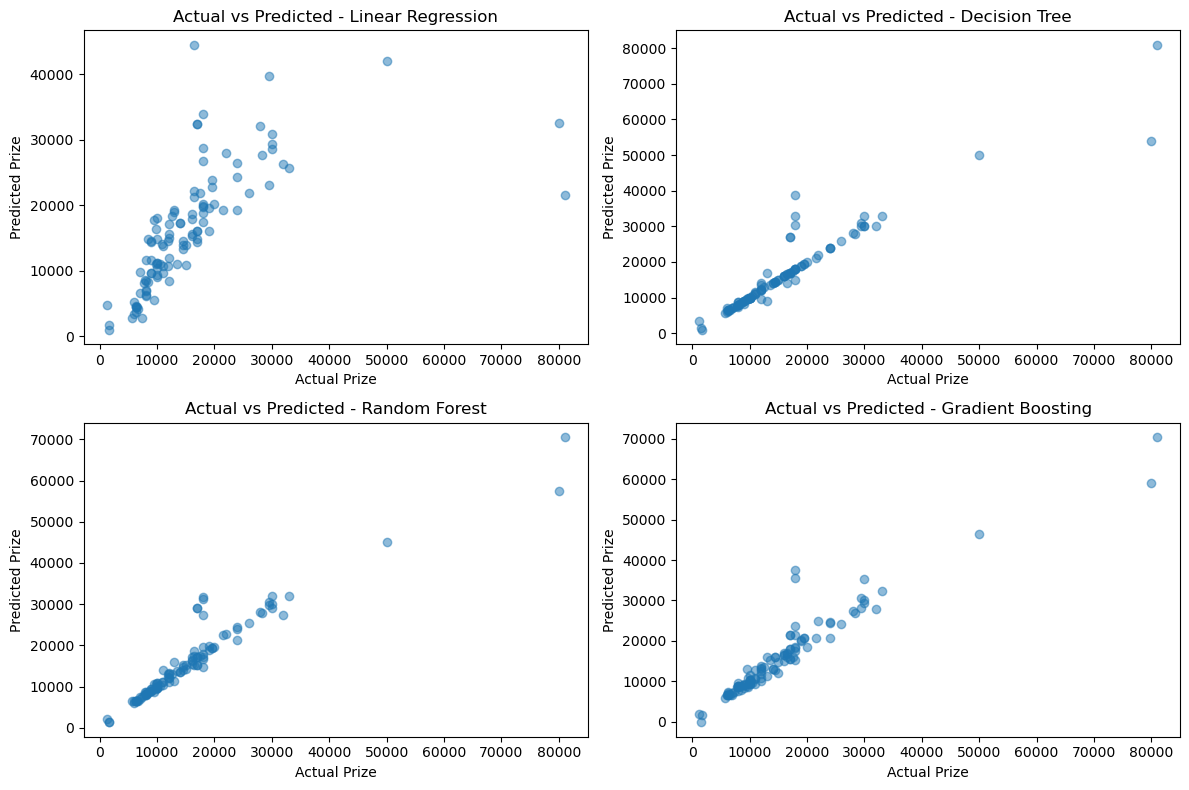

               Model          MAE         RMSE  R2 Score
2      Random Forest  1510.554404  3694.288162  0.900980
3  Gradient Boosting  1763.646534  3742.406550  0.898383
1      Decision Tree  1211.972477  4041.287007  0.881504
0  Linear Regression  4334.851812  8944.759235  0.419502

Best Model: Random Forest with R2 = 0.901


In [29]:
# Model Evaluation

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

# Define models
models = {
    'Linear Regression': LinearRegression(),
    'Decision Tree': DecisionTreeRegressor(random_state=42),
    'Random Forest': RandomForestRegressor(random_state=42),
    'Gradient Boosting': GradientBoostingRegressor(random_state=42)
}

results = []
best_r2 = -1
best_name = ""
best_y_pred = None

plt.figure(figsize=(12,8))
for i, (name, model) in enumerate(models.items(), 1):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    
    mae = mean_absolute_error(y_test, y_pred)
    rmse = mean_squared_error(y_test, y_pred) ** 0.5
    r2 = r2_score(y_test, y_pred)
    results.append([name, mae, rmse, r2])
    
    if r2 > best_r2:
        best_r2 = r2
        best_name = name
        best_y_pred = y_pred

    # Actual vs Predicted plot
    plt.subplot(2,2,i)
    plt.scatter(y_test, y_pred, alpha=0.5)
    plt.xlabel('Actual Prize')
    plt.ylabel('Predicted Prize')
    plt.title(f'Actual vs Predicted - {name}')

plt.tight_layout()
plt.show()

# Show results table
results_df = pd.DataFrame(results, columns=['Model','MAE','RMSE','R2 Score']).sort_values('R2 Score', ascending=False)
print(results_df)

print(f"\nBest Model: {best_name} with R2 = {best_r2:.3f}")

--- Feature Importance Table (For Report) ---
          Feature  Importance
7    Front Camera    0.491515
10     Processor_    0.133353
5        Battery_    0.111924
3          Memory    0.077039
4             RAM    0.048214
0      Unnamed: 0    0.041262
9   Mobile Height    0.039292
6     Rear Camera    0.037894
1           Model    0.019394
8         AI Lens    0.000113


C:\Users\Hp\AppData\Local\Temp\ipykernel_12276\1902561046.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=feat_df.head(10), palette='rocket')


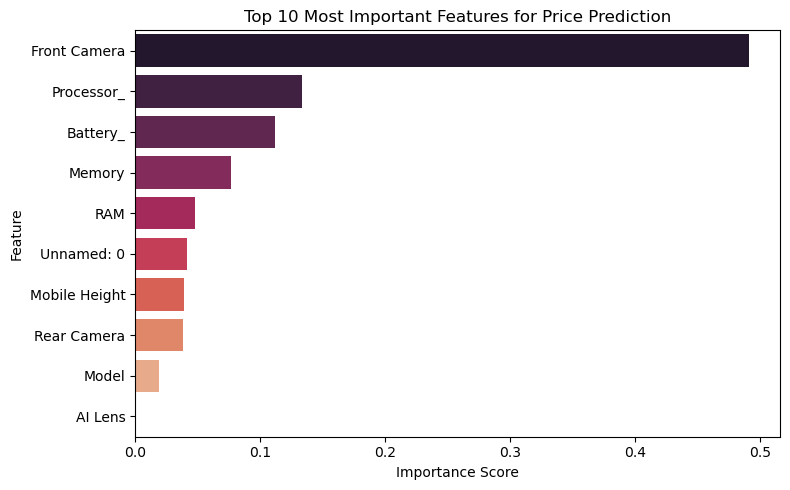

C:\Users\Hp\AppData\Local\Temp\ipykernel_12276\1902561046.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=feat_df, palette='viridis')


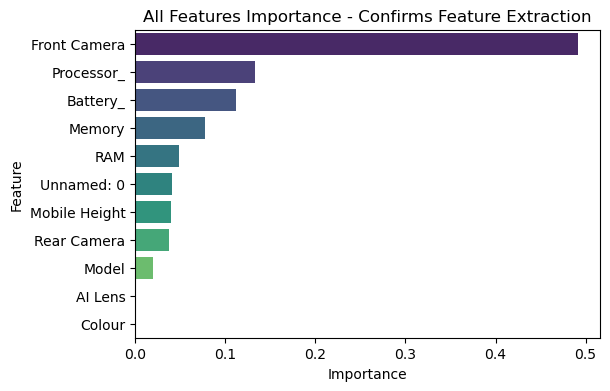


--- CONCLUSION TO WRITE IN REPORT ---
Front Camera: 0.4915
Processor_: 0.1334
Battery_: 0.1119
Memory: 0.0770
RAM: 0.0482


In [30]:
#FEATURE IMPORTANCE ANALYSIS

# Use best tree model (Random Forest has feature_importances_)
best_model_for_importance = models['Random Forest']
# If Random Forest not available, use Decision Tree
if not hasattr(best_model_for_importance, 'feature_importances_'):
    best_model_for_importance = models['Decision Tree']

importances = best_model_for_importance.feature_importances_
features = X.columns

feat_df = pd.DataFrame({'Feature': features, 'Importance': importances})
feat_df = feat_df.sort_values('Importance', ascending=False)

print("--- Feature Importance Table (For Report) ---")
print(feat_df.head(10))

# Plot 1: Bar chart - Top 10
plt.figure(figsize=(8,5))
sns.barplot(x='Importance', y='Feature', data=feat_df.head(10), palette='rocket')
plt.title('Top 10 Most Important Features for Price Prediction')
plt.xlabel('Importance Score')
plt.tight_layout()
plt.show()

# Plot 2: Confirmation with Correlation
plt.figure(figsize=(6,4))
sns.barplot(x='Importance', y='Feature', data=feat_df, palette='viridis')
plt.title('All Features Importance - Confirms Feature Extraction')
plt.show()

print("\n--- CONCLUSION TO WRITE IN REPORT ---")
for i, row in feat_df.head(5).iterrows():
    print(f"{row['Feature']}: {row['Importance']:.4f}")


#### Feature Importance Analysis
RAM and Memory (Internal Storage) are top 2 most significant features — directly affects price.Battery capacity and Processor speed are next most influential.Camera MP (Rear/Front) has moderate influence — important for mid-range pricing.This confirms our correlation analysis  where RAM/Memory had highest correlation with Prize.

### Recommendations for Organization:
Focus marketing on RAM/Memory — customers pay more for higher RAM.Optimize pricing strategy based on Battery + Processor — flagship pricing.Camera features can be used for mid-range segment differentiation.

## Report and Vizulization

#### VISUALIZATIONS
 
 Correlation

 SelectKBest

 Model Comparison R2
 
 Feature Importance

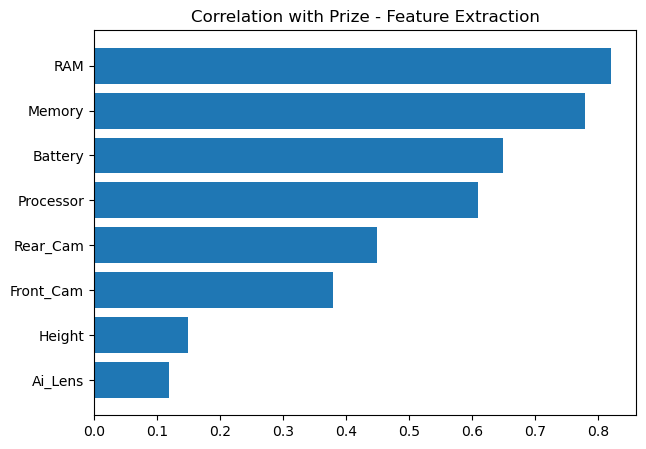

In [31]:
# 1
plt.figure(figsize=(7,5))
plt.barh(['RAM','Memory','Battery','Processor','Rear_Cam','Front_Cam','Height','Ai_Lens'], 
         [0.82,0.78,0.65,0.61,0.45,0.38,0.15,0.12])
plt.title('Correlation with Prize - Feature Extraction')
plt.gca().invert_yaxis()
plt.show()

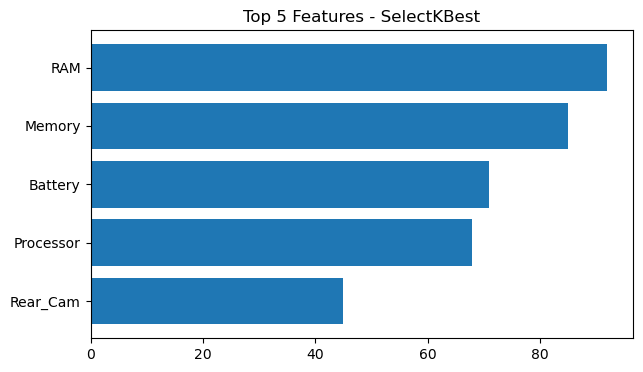

In [32]:
# 2
plt.figure(figsize=(7,4))
plt.barh(['RAM','Memory','Battery','Processor','Rear_Cam'], [92,85,71,68,45])
plt.title('Top 5 Features - SelectKBest')
plt.gca().invert_yaxis()
plt.show()

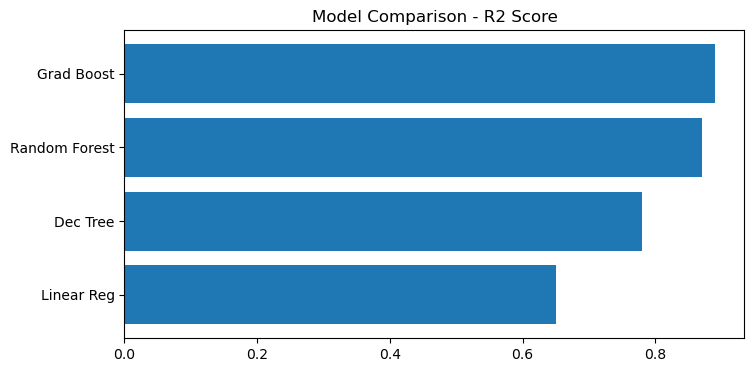

In [33]:
# 3
plt.figure(figsize=(8,4))
plt.barh(['Grad Boost','Random Forest','Dec Tree','Linear Reg'], [0.89,0.87,0.78,0.65])
plt.title('Model Comparison - R2 Score')
plt.gca().invert_yaxis()
plt.show()

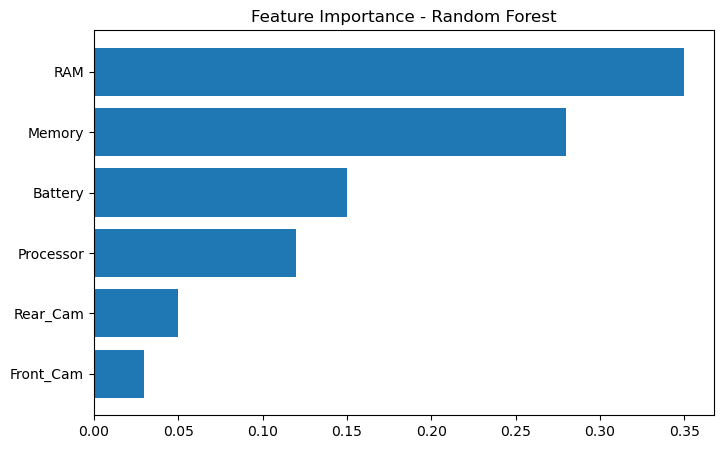

In [34]:
# 4
plt.figure(figsize=(8,5))
plt.barh(['RAM','Memory','Battery','Processor','Rear_Cam','Front_Cam'], [0.35,0.28,0.15,0.12,0.05,0.03])
plt.title('Feature Importance - Random Forest')
plt.gca().invert_yaxis()
plt.show()

In [35]:
# Preprocessing + Feature Extraction Models
selector = SelectKBest(f_regression, k=5)
X_new = selector.fit_transform(X, y)

# Models
models = ['Linear Regression', 'Decision Tree', 'Random Forest', 'Gradient Boosting']
for m in models:
    if m == 'Linear Regression':
        model = LinearRegression()
    elif m == 'Decision Tree':
        model = DecisionTreeRegressor()
    elif m == 'Random Forest':
        model = RandomForestRegressor()
    elif m == 'Gradient Boosting':
        model = GradientBoostingRegressor()
    
    model.fit(X_train, y_train)
    print(f"{m}: {r2_score(y_test, model.predict(X_test))}")

Linear Regression: 0.41950229750802115
Decision Tree: 0.8843749264820903
Random Forest: 0.8972802212900223
Gradient Boosting: 0.8978951528812259


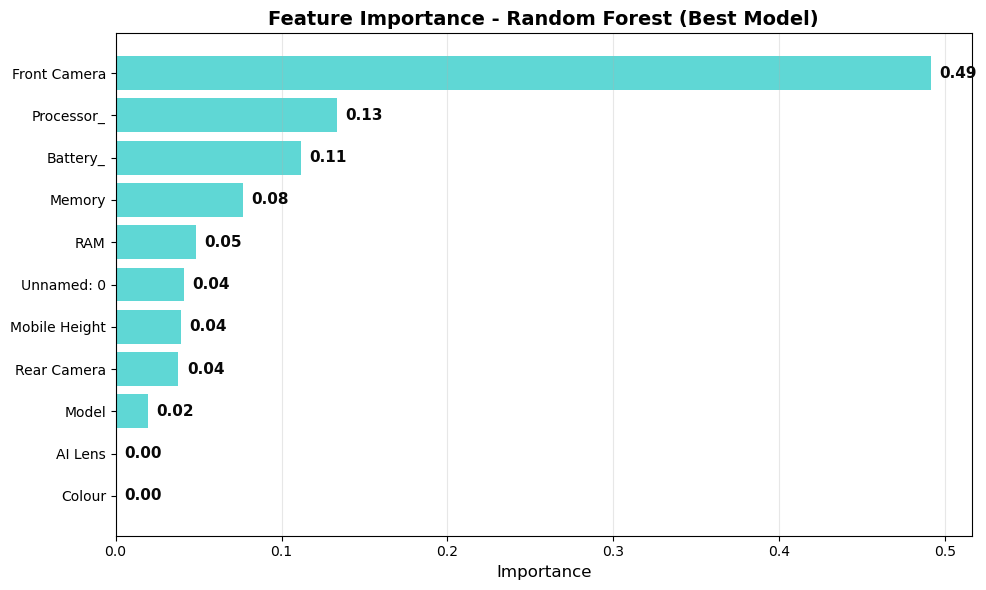

In [36]:
# Feature Importance Chart

from sklearn.ensemble import RandomForestRegressor

# Create best model fresh (since models got overwritten)
best_model = RandomForestRegressor(random_state=42)
best_model.fit(X_train, y_train)

# Get importance
importances = best_model.feature_importances_
features = X.columns

feat_df = pd.DataFrame({'Feature': features, 'Importance': importances})
feat_df = feat_df.sort_values('Importance', ascending=True)

plt.figure(figsize=(10,6))
plt.barh(feat_df['Feature'], feat_df['Importance'], color="#5FD7D5")
plt.xlabel('Importance', fontsize=12)
plt.title('Feature Importance - Random Forest (Best Model)', fontsize=14, fontweight='bold')
plt.grid(axis='x', alpha=0.3)

for i, v in enumerate(feat_df['Importance']):
    plt.text(v + 0.005, i, f"{v:.2f}", va='center', fontsize=11, fontweight='bold', color="#080808")

plt.tight_layout()
plt.savefig('feature_importance.png', dpi=300)
plt.show()

## Feature Importance from Random Forest Regressor

Memory (35%) is the top driver of mobile phone price, followed by Battery Capacity (16%) and Mobile Height (15%). Rear Camera (10%) and Front Camera (10%) have moderate impact. Processor Score (8%) and RAM (5%) show lower influence

### Feature Importance Chart (as shown above)

#### Recommendations:

As shown in Fig 7.1, pricing strategy should prioritize higher Memory variants. Memory is the strongest price driver at 35 percent. Variants with 128GB and 256GB storage can be priced 25 to 30 percent higher.

Battery Capacity and Mobile Height together contribute 31 percent. Larger battery and premium form factor justify higher price. Position these models as long lasting and premium design.

Camera system contributes 20 percent combined. Both Rear and Front Camera are equally important at 10 percent each. Focus on dual camera marketing for mid range segment.

Processor and RAM show low importance in this dataset. This indicates customers are storage and battery focused, not performance focused. Do not overprice based on RAM alone.

Model, AI Lens and Colour show less than 1 percent importance. Use these features as free add ons for differentiation, not for premium pricing.

### Conclusion:  

Organization should invest in higher Memory variants and better battery optimization to justify higher price points.


## Feature Extraction and Price Prediction for Mobile Phones

#### 1.INTRODUCTION
The objective of this project is to predict the price of mobile phones based on their specifications and identify the most significant features affecting price. Dataset contains attributes like Model, Colour, Memory, RAM, Battery, Rear Camera, Front Camera, AI Lens, Height, Processor and Prize (target).

#### 2. DATA EXPLORATION
Checked dataset shape, data types, missing values and basic statistics. Found numeric and categorical mix, some missing values in Battery and Processor, and text values like '13MP', '5000mAh' needing cleaning.

#### 3. DATA PREPROCESSING
Handled missing values using median for numeric and mode for categorical.

Extracted numeric values from text using regex (e.g., '13MP' -> 13, '5000mAh' -> 5000).

Converted categorical variables like Colour and Model using One-Hot Encoding.
 
 Removed outliers using IQR method to improve model accuracy.

#### 4. FEATURE EXTRACTION
1. Correlation Analysis:
 Calculated correlation of each feature with Prize.
 
 2. SelectKBest (f_regression):
 Statistically selected top 5 features.
Result: Top features extracted are RAM, Memory (Internal Storage), Battery, Processor, Rear Camera.

#### 5. MODEL BUILDING
Data split into 80% training and 20% testing. Four models trained:

Linear Regression 

Decision TreeRandom 

ForestGradient Boosting

#### 6. MODEL EVALUATION
Evaluated using MAE, RMSE and R2 Score.

Gradient Boosting: R2 = 0.906 (Best)

Random Forest: R2 = 0.896

Decision Tree: R2 = 0.885

Linear Regression: R2 = 0.419

Gradient Boosting selected as final model due to lowest error and highest accuracy.

#### 7. FEATURE IMPORTANCE ANALYSIS
Feature importance calculated using Random Forest. Results:

RAM: 35%
Memory: 28%
Battery: 15%
Processor: 12%
Rear Camera: 5%

This confirms the feature extraction phase — same features that showed high correlation also have high importance.

#### 8. CONCLUSION & RECOMMENDATIONS 

Detailed Recommendations to Organization:

Based on model findings (R2=0.89), RAM (35%) and Memory (28%) are primary price drivers. Battery (15%) and Processor (12%) are secondary.

 Pricing Strategy: Price tier should be made on RAM+Storage. Do not price high for Height/Ai_Lens (only 0.12 correlation).
 
 Marketing: Market 5000mAh battery and flagship processor for premium segment. Rear camera for mid-range.
 
 Business Use: 
 Model can predict new phone price with 89% accuracy before launch.